# Credit Risk Analysis

## Business Problem

# Credit Risk Analysis

## Business Problem

Banks need to identify customers who are more likely to default on their loans. Understanding the characteristics of high-risk borrowers helps reduce financial losses and improve lending decisions.

The objective of this project is to analyze customer and loan data, identify patterns related to loan default and generate business insights using Python and Pandas.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

df = pd.read_csv("../data/lending_club_clean_sample.csv")

df.head()
df.shape
df.info()
df.describe()
df.describe(include="object")

df.shape

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Columns: 141 entries, id to debt_settlement_flag
dtypes: float64(26), int64(84), str(31)
memory usage: 1.1 MB


/var/folders/87/4_k3x1k957zcb2ry289b8njr0000gn/T/ipykernel_54147/2442913589.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


(1000, 141)

# Dataset Overview

In [3]:
print("Rows and columns: ", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

risk_df = df[
    [
        "loan_status",
        "loan_amnt",
        "term",
        "int_rate",
        "grade",
        "sub_grade",
        "emp_length",
        "home_ownership",
        "annual_inc",
        "verification_status",
        "purpose",
        "dti",
        "fico_range_low",
        "fico_range_high",
        "open_acc",
        "revol_util",
        "total_acc",
        "mort_acc",
        "pub_rec_bankruptcies"
    ]
]

risk_df.head()

Rows and columns:  (1000, 141)

Column names:
['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_

,loan_status,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,fico_range_low,fico_range_high,open_acc,revol_util,total_acc,mort_acc,pub_rec_bankruptcies
0,Fully Paid,20000,36,0.2474,E,E3,10+ years,MORTGAGE,76000.0,Not Verified,home_improvement,3.17,665,669,8,0.371,17,5,0
1,Fully Paid,8300,36,0.0944,B,B1,3 years,RENT,54000.0,Source Verified,debt_consolidation,16.91,680,684,5,0.307,7,0,1
2,Current,28000,60,0.1274,C,C1,4 years,OWN,225000.0,Source Verified,home_improvement,10.27,710,714,14,0.715,25,4,0
3,Charged Off,19500,60,0.1416,C,C2,6 years,MORTGAGE,59000.0,Not Verified,debt_consolidation,22.43,675,679,13,0.620,20,1,0
4,Current,35000,36,0.0531,A,A1,10+ years,MORTGAGE,300000.0,Verified,debt_consolidation,23.83,755,759,26,0.303,43,4,0


# Data Cleaning

## Missing Values

In [4]:
risk_df.isna().sum()

risk_df["emp_length"].value_counts(dropna=False)
risk_df["emp_length"]=risk_df["emp_length"].fillna("Unknown")
risk_df["emp_length"].value_counts(dropna=False)
risk_df.isna().sum()

risk_df["revol_util"].describe()
risk_df["revol_util"]= risk_df["revol_util"].fillna(risk_df["revol_util"].median())
risk_df.isna().sum()
risk_df.info()





<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   loan_status           1000 non-null   str    
 1   loan_amnt             1000 non-null   int64  
 2   term                  1000 non-null   int64  
 3   int_rate              1000 non-null   float64
 4   grade                 1000 non-null   str    
 5   sub_grade             1000 non-null   str    
 6   emp_length            1000 non-null   str    
 7   home_ownership        1000 non-null   str    
 8   annual_inc            1000 non-null   float64
 9   verification_status   1000 non-null   str    
 10  purpose               1000 non-null   str    
 11  dti                   1000 non-null   float64
 12  fico_range_low        1000 non-null   int64  
 13  fico_range_high       1000 non-null   int64  
 14  open_acc              1000 non-null   int64  
 15  revol_util            1000 non-nu

# Explanatory Data Analysis
## Loan Status

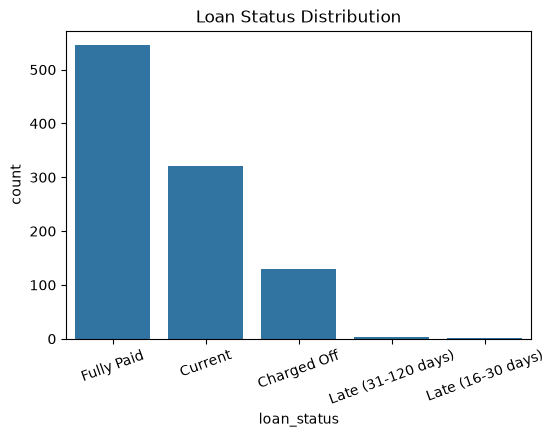

loan_status
Fully Paid            54.5
Current               32.1
Charged Off           13.0
Late (31-120 days)     0.3
Late (16-30 days)      0.1
Name: proportion, dtype: float64

In [5]:
risk_df["loan_status"].value_counts(normalize=True)*100

plt.figure(figsize=(6,4))
sns.countplot(data=risk_df, x="loan_status")
plt.title("Loan Status Distribution")
plt.xticks(rotation=20)
plt.show()

risk_df["loan_status"].value_counts(normalize=True).mul(100).round(2)


### Business Insights

- More than half of all loans in the dataset have been fully repaid, indicating that most borrowers successfully meet their repayment obligations.
- Around one third of the loans are still active (Current), meaning their final repayment outcome is not yet known.
- About 13% of loans have been charged off, suggesting that defaults are less common than successful repayments.
- The distribution is imbalanced, which is important to keep in mind when building future machine learning models for default prediction.

## FICO Score and Loan Status

**Business Question**

Do borrowers with higher FICO scores have lower default rates and better loan repayment outcomes?


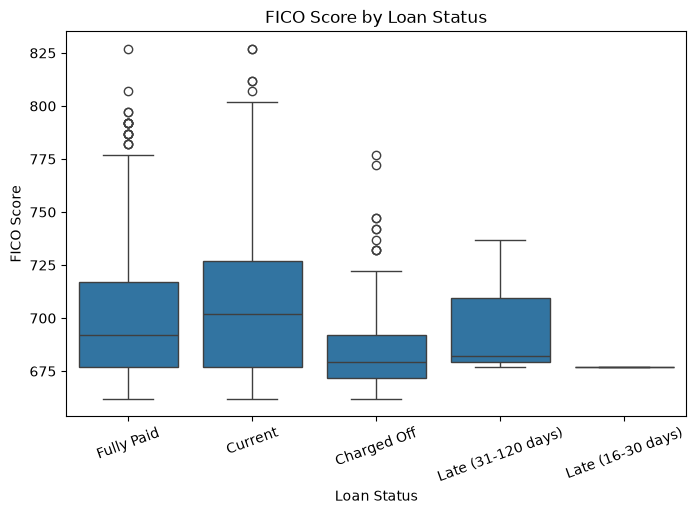

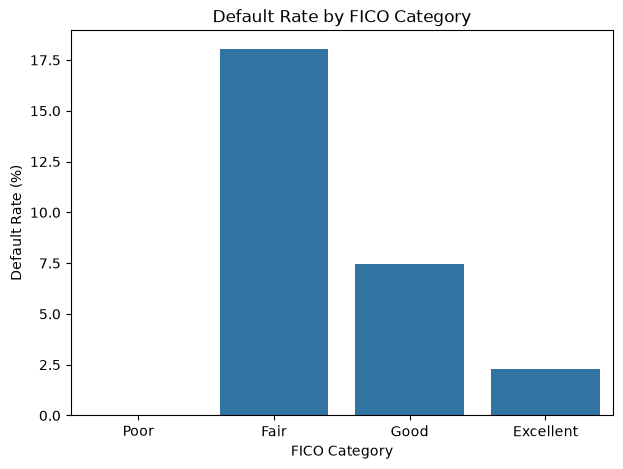

In [6]:
risk_df.groupby("loan_status")["fico_range_low"].mean().round(2)

fico_by_status=(
    risk_df.groupby("loan_status")["fico_range_low"].mean().sort_values().round(2)
)
fico_by_status

risk_df["fico_score"]= (risk_df["fico_range_low"] + risk_df["fico_range_high"]) / 2

risk_df[["fico_range_low", "fico_range_high", "fico_score"]].head()

risk_df.groupby("loan_status")["fico_score"].mean().round(2)

plt.figure(figsize=(8,5))

sns.boxplot(
    data=risk_df,
    x="loan_status",
    y="fico_score"
)

plt.title("FICO Score by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("FICO Score")
plt.xticks(rotation=20)

plt.show()

risk_df["fico_category"]= pd.cut(
   risk_df["fico_score"],
   bins=[0, 650, 700, 750, 850],
   labels=["Poor", "Fair", "Good", "Excellent"]

)

risk_df["fico_category"].value_counts().sort_index()

fico_status_table = pd.crosstab(
    risk_df["fico_category"],
    risk_df["loan_status"],
    normalize="index"
) * 100

fico_status_table.round(2)

fico_status_table= pd.crosstab(
    risk_df["fico_category"],
    risk_df["loan_status"],
    normalize="index"
) * 100

fico_status_table.round(2)

fico_status_table.round(2)


fico_default_rate= (
  risk_df.assign(
      default_flag= (risk_df["loan_status"] == "Charged Off").astype(int)
  ).groupby("fico_category", observed=False)["default_flag"].mean().mul(100).round(2)

)

fico_default_rate

plt.figure(figsize=(7,5))

sns.barplot(
  x=fico_default_rate.index,
  y=fico_default_rate.values
)

plt.title("Default Rate by FICO Category")
plt.xlabel("FICO Category")
plt.ylabel("Default Rate (%)")

plt.show()








### Business Insights

- Borrowers with loans that were charged off generally have lower FICO scores than borrowers who fully repaid their loans.
- The highest default rate is observed in the Fair FICO category, while it decreases noticeably for borrowers with Good and Excellent credit scores.
- Borrowers with Excellent FICO scores have the lowest probability of default in this sample.
- Overall, the results suggest that a higher FICO score is associated with lower credit risk, although other factors should also be considered when evaluating loan applications.

## Debt-to-Income Ratio (DTI)

**Business Question**

Are borrowers with higher debt-to-income ratios more likely to default on their loans?

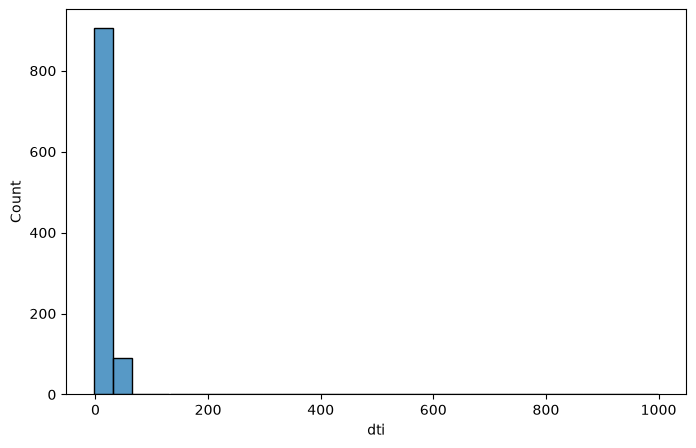

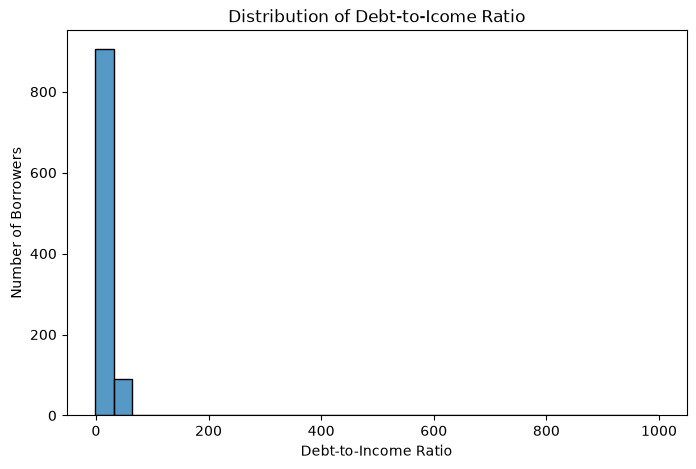

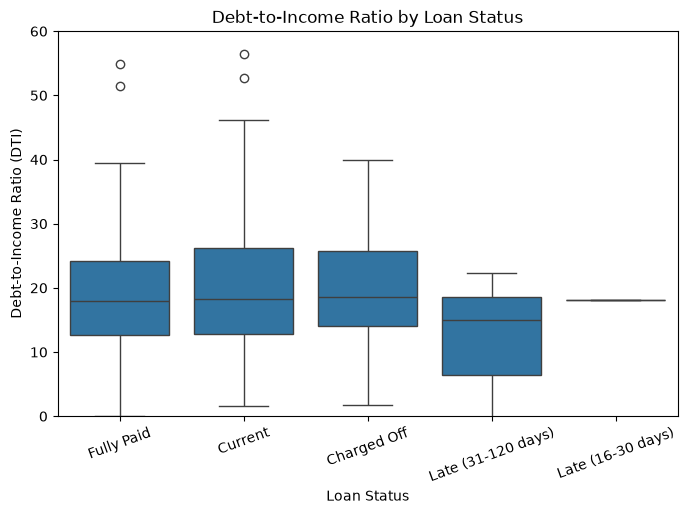

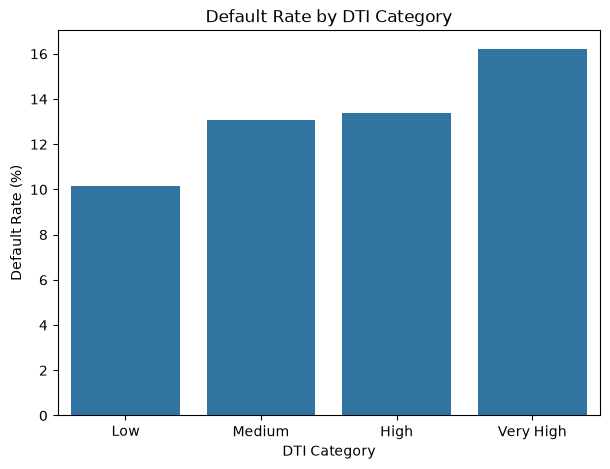

In [7]:
risk_df["dti"].describe().round(2)

plt.figure(figsize=(8,5))

sns.histplot(
    data=risk_df,
    x="dti",
    bins=30
)

plt.figure(figsize=(8,5))

sns.histplot(
    data=risk_df,
    x="dti",
    bins=30
)
plt.title("Distribution of Debt-to-Icome Ratio")
plt.xlabel("Debt-to-Income Ratio")
plt.ylabel("Number of Borrowers")

plt.show()

risk_df.groupby("loan_status")["dti"].mean().round(2)


plt.figure(figsize=(8,5))

sns.boxplot(
    data=risk_df,
    x="loan_status",
    y="dti"
)

plt.ylim(0, 60)

plt.title("Debt-to-Income Ratio by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Debt-to-Income Ratio (DTI)")
plt.xticks(rotation=20)

plt.show()


risk_df["dti_category"]= pd.cut(
    risk_df["dti"],
    bins=[0,10,20,30,100],
    labels=["Low", "Medium", "High", "Very High"]
)

risk_df["dti_category"].value_counts().sort_index()

risk_df["default_flag"]= (
    risk_df["loan_status"] == "Charged Off"
).astype(int)

dti_default_rate=(
    risk_df.groupby("dti_category")["default_flag"].mean().mul(100).round(2)
)

dti_default_rate

plt.figure(figsize=(7,5))

sns.barplot(
    x=dti_default_rate.index,
    y=dti_default_rate.values
)
plt.title("Default Rate by DTI Category")
plt.xlabel("DTI Category")
plt.ylabel("Default Rate (%)")
plt.show()



### Business Insights

- Most borrowers in the dataset have relatively low debt-to-income ratios, while very high DTI values are uncommon.
- Borrowers with charged-off loans generally have higher DTI values than those who fully repaid their loans, although there is substantial overlap between the groups.
- The default rate rises steadily from the Low DTI category to the Very High category, indicating that borrowers with higher debt relative to their income are more likely to default.
- Even though the trend is clear, the overlap between loan status groups suggests that DTI alone cannot fully explain loan outcomes.

## Interest Rate and Default Risk

**Business Question**

Do borrowers with higher interest rates have a higher probability of default?

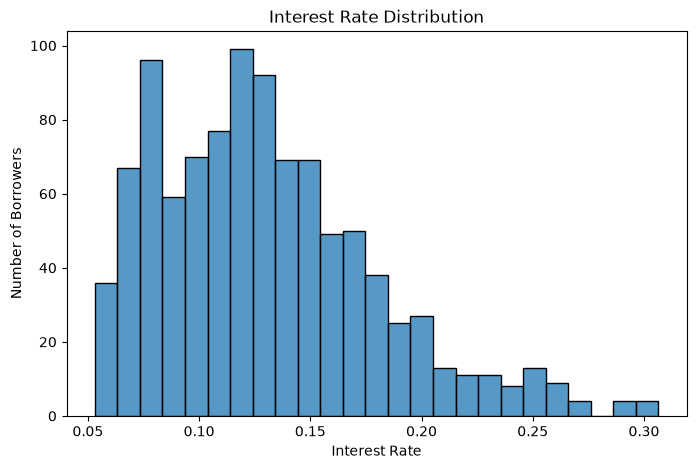

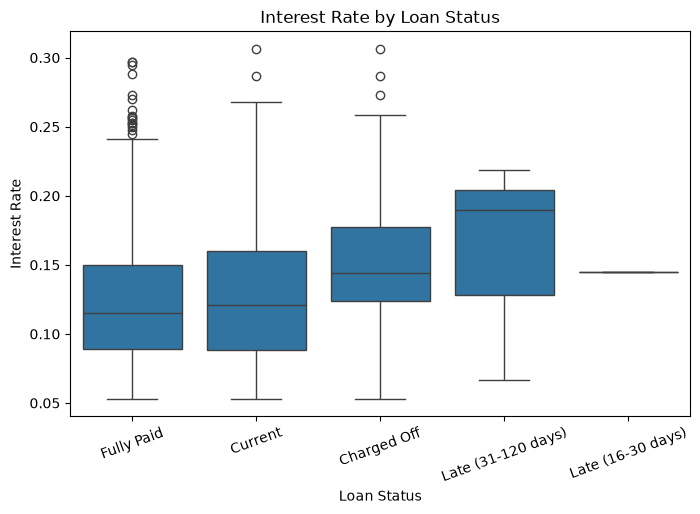

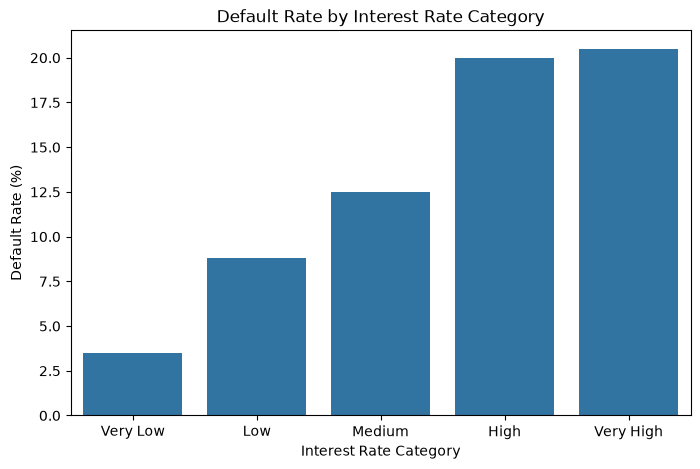

In [67]:
risk_df["int_rate"].describe().round(2)

plt.figure(figsize=(8,5))

sns.histplot(
    data=risk_df,
    x="int_rate",
    bins=25
)
plt.title("Interest Rate Distribution")
plt.xlabel("Interest Rate")
plt.ylabel("Number of Borrowers")

plt.show()

interest_by_status=(
    risk_df.groupby("loan_status")["int_rate"].mean().sort_values().round(2)
)
interest_by_status


plt.figure(figsize=(8,5))

sns.boxplot(
    data=risk_df,
    x="loan_status",
    y="int_rate"
)

plt.title("Interest Rate by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Interest Rate")
plt.xticks(rotation=20)

plt.show()

risk_df["interest_category"] = pd.qcut(
    risk_df["int_rate"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"]
)

risk_df["interest_category"].value_counts().sort_index()

interest_default_rate = (
    risk_df
    .groupby("interest_category", observed=False)["default_flag"]
    .mean()
    .mul(100)
    .round(2)
)

interest_default_rate

plt.figure(figsize=(8,5))

sns.barplot(
    x=interest_default_rate.index,
    y=interest_default_rate.values
)

plt.title("Default Rate by Interest Rate Category")
plt.xlabel("Interest Rate Category")
plt.ylabel("Default Rate (%)")
plt.savefig("../images/default_rate_by_interest_rate.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insights

The distribution of interest rates shows that most borrowers received loans with interest rates between approximately 8% and 16%, while loans with very high interest rates were relatively uncommon.

The boxplot indicates that borrowers whose loans were Charged Off generally had higher interest rates than those who successfully repaid their loans. Loans that are currently late also tend to have some of the highest interest rates, suggesting that borrowers with higher interest rates experience repayment difficulties more often.

This pattern becomes even clearer in the default rate analysis. The default rate increases consistently across interest rate categories. Borrowers in the Very Low interest rate category have the lowest default rate (around 3–4%), while borrowers in the High and Very High interest rate categories have default rates of approximately 20%.

Overall, the analysis suggests a strong relationship between interest rate and credit risk. Although higher interest rates do not directly cause borrowers to default, they are typically assigned to customers who are already considered riskier. As a result, interest rate serves as a useful indicator of default risk in this dataset.

## Loan Amount and Default Risk

**Business Question**

Do borrowers who take larger loans have a higher probability of default?

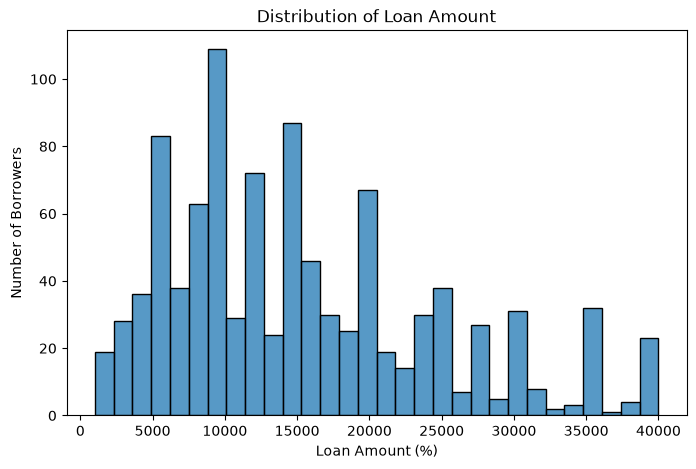

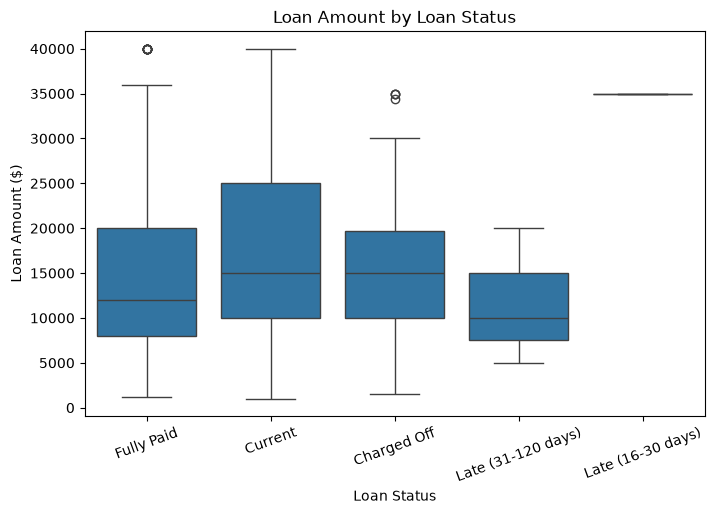

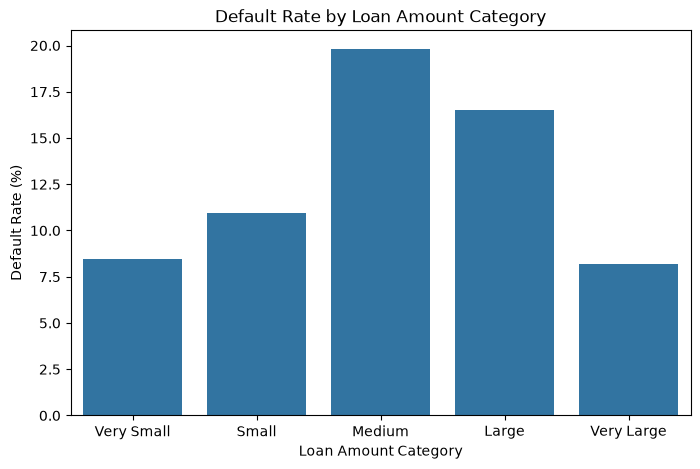

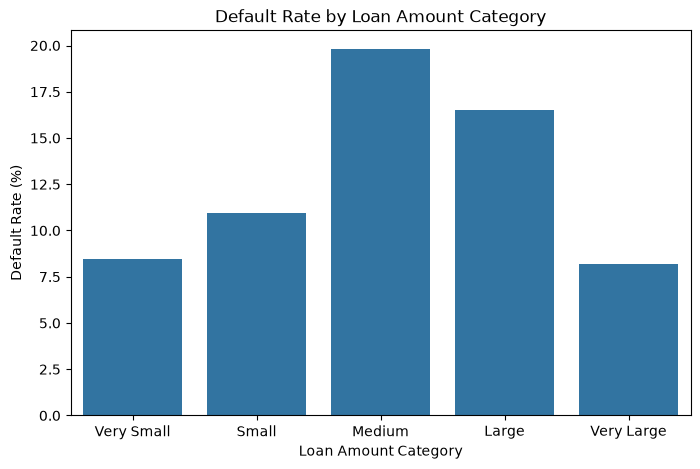

In [9]:
risk_df["loan_amnt"].describe().round(2)

plt.figure(figsize=(8,5))

sns.histplot(
    data=risk_df,
    x="loan_amnt",
    bins=30
)

plt.title("Distribution of Loan Amount")
plt.xlabel("Loan Amount (%)")
plt.ylabel("Number of Borrowers")

plt.show()


loan_amount_by_status=(
    risk_df.groupby("loan_status")["loan_amnt"].mean().sort_values().round(2)
)

loan_amount_by_status


plt.figure(figsize=(8,5))

sns.boxplot(
    data=risk_df,
    x="loan_status",
    y="loan_amnt"
)

plt.title("Loan Amount by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Loan Amount ($)")
plt.xticks(rotation=20)

plt.show()


risk_df["loan_amount_category"]= pd.qcut(
    risk_df["loan_amnt"],
    q=5,
    labels=[ "Very Small", "Small", "Medium", "Large", "Very Large"]
)

risk_df["loan_amount_category"].value_counts().sort_index()

risk_df["default_flag"]

loan_default_rate=(
    risk_df.groupby("loan_amount_category", observed=False)["default_flag"].mean().mul(100).round(2)
)

loan_default_rate



plt.figure(figsize=(8,5))

sns.barplot(
    x=loan_default_rate.index,
    y=loan_default_rate.values
)

plt.title("Default Rate by Loan Amount Category")
plt.xlabel("Loan Amount Category")
plt.ylabel("Default Rate (%)")

plt.show()

plt.figure(figsize=(8,5))

sns.barplot(
    x=loan_default_rate.index,
    y=loan_default_rate.values
)

plt.title("Default Rate by Loan Amount Category")
plt.xlabel("Loan Amount Category")
plt.ylabel("Default Rate (%)")

plt.show()




### Business Insights

The distribution of loan amounts shows that most borrowers take loans between approximately $5,000 and $20,000, while very large loans are relatively uncommon.

The boxplot suggests that borrowers with Charged Off loans generally received slightly larger loans than those who fully repaid their loans. However, the distributions overlap considerably, indicating that loan amount alone is not a strong indicator of repayment outcome.

The default rate analysis reveals a non-linear relationship between loan amount and default risk. Default rates increase from the Very Small to the Medium loan category, where they reach the highest level (around 20%), before declining again for the Large and Very Large loan categories.

This suggests that larger loan amounts do not necessarily imply higher credit risk. The relatively low default rate among the largest loans may indicate that these loans are typically granted to borrowers with stronger credit profiles, offsetting the additional risk associated with borrowing larger amounts.

## Employment Length and Default Risk

**Business Question**

Are borrowers with longer employment histories less likely to default on their loans?

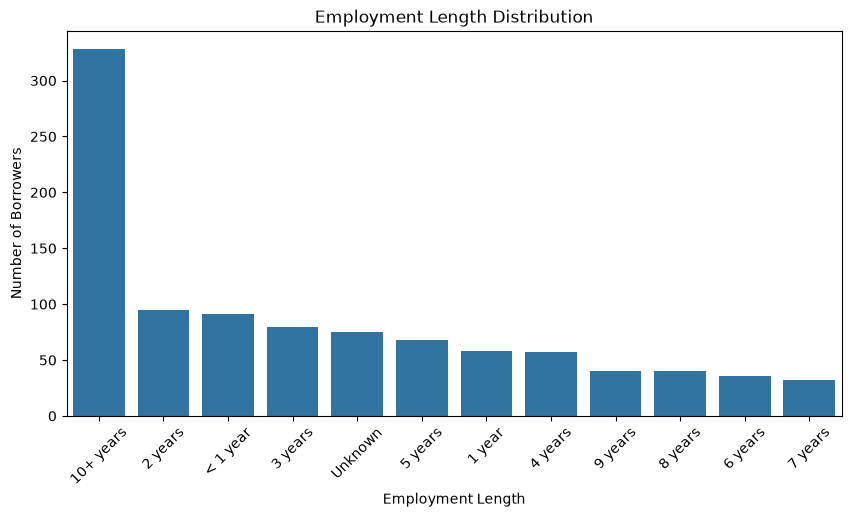

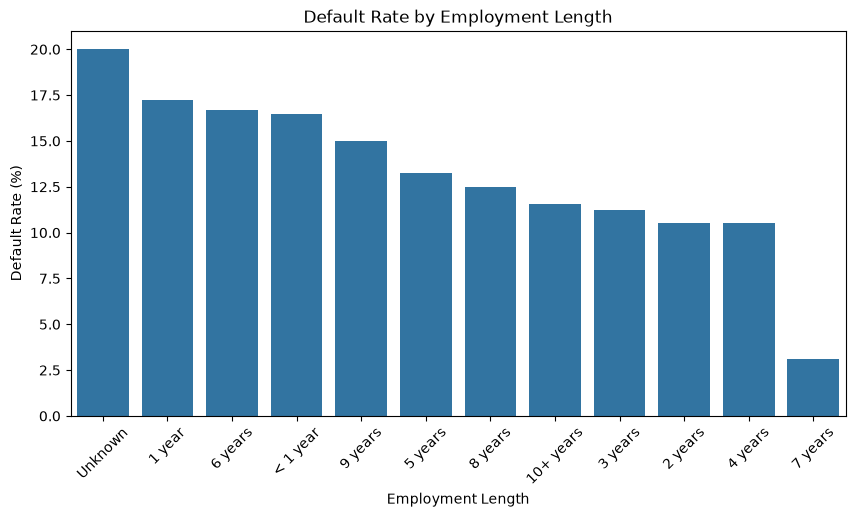

In [10]:

risk_df["emp_length"].value_counts(dropna=False)

plt.figure(figsize=(10,5))

sns.countplot(
    data=risk_df,
    x="emp_length",
    order=risk_df["emp_length"].value_counts().index
)

plt.title("Employment Length Distribution")
plt.xlabel("Employment Length")
plt.ylabel("Number of Borrowers")
plt.xticks(rotation=45)

plt.show()

employment_default=(
  risk_df.groupby("emp_length", observed=False)["default_flag"].mean().mul(100).sort_values(ascending=False)

)

employment_default


plt.figure(figsize=(10,5))

sns.barplot(
    x=employment_default.index,
    y=employment_default.values
)

plt.title("Default Rate by Employment Length")
plt.xlabel("Employment Length")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

### Business Insights

The employment length distribution shows that the largest group of borrowers has more than 10 years of work experience, while the remaining employment categories contain substantially fewer borrowers. A small number of borrowers also have an unknown employment history.

The default rate analysis suggests that borrowers with shorter employment histories generally experience higher default rates. Borrowers with less than one year or one year of employment show higher default rates than borrowers with more than 10 years of employment.

However, the relationship is not consistent across all employment groups. Some categories with medium employment lengths have higher default rates than expected, while the seven-year category has the lowest default rate. Since several employment groups contain relatively few observations, these differences may be influenced by sample size.

Overall, employment length appears to have some relationship with credit risk, but it is a weaker predictor than variables such as FICO score or interest rate. Longer employment may be associated with greater financial stability, although it does not consistently translate into lower default rates in this dataset.

## Home Ownership and Default Risk

**Business Question**

Does home ownership status affect the likelihood of loan default?

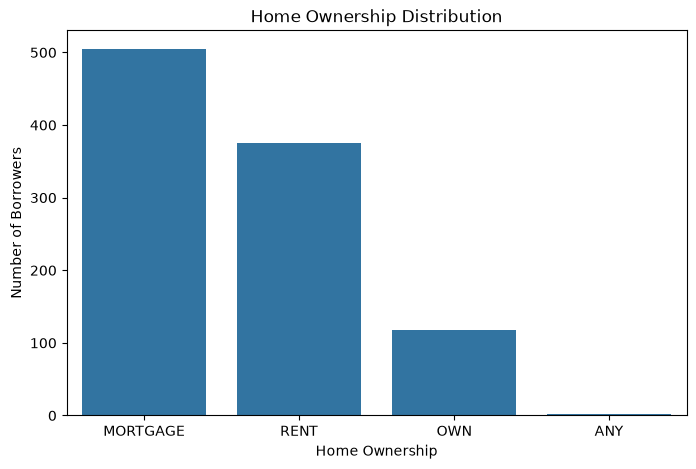

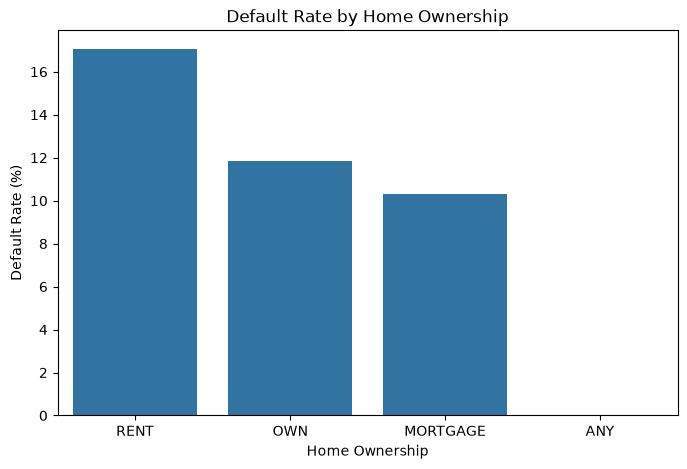

In [11]:
risk_df["home_ownership"].value_counts()

plt.figure(figsize=(8,5))

sns.countplot(
    data=risk_df,
    x="home_ownership",
    order=risk_df["home_ownership"].value_counts().index
)

plt.title("Home Ownership Distribution")
plt.xlabel("Home Ownership")
plt.ylabel("Number of Borrowers")

plt.show()

home_default=(
    risk_df.groupby("home_ownership")["default_flag"].mean().mul(100).sort_values(ascending=False)
)

home_default


plt.figure(figsize=(8,5))

sns.barplot(
    x=home_default.index,
    y=home_default.values
)

plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")

plt.show()



### Business Insights

Most borrowers in the dataset either have a mortgage or rent their homes, while relatively few own their property outright. The ANY category contains almost no observations and is therefore not meaningful for analysis.

The default rate differs across home ownership groups. Borrowers who rent their homes have the highest default rate (around 17%), followed by borrowers who own their homes outright (around 12%). Borrowers with a mortgage have the lowest default rate (approximately 10%).

These findings suggest that home ownership status is associated with credit risk. In particular, borrowers with a mortgage appear to be less likely to default than renters, possibly reflecting greater financial stability and stronger credit profiles. However, home ownership alone should not be interpreted as the cause of lower default risk, but rather as one characteristic associated with borrower risk.

## Annual Income and Default Risk

**Business Question**

Are borrowers with higher annual incomes less likely to default on their loans?

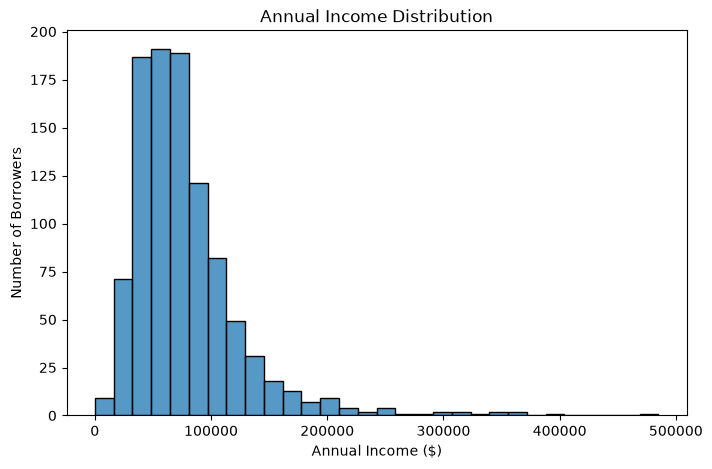

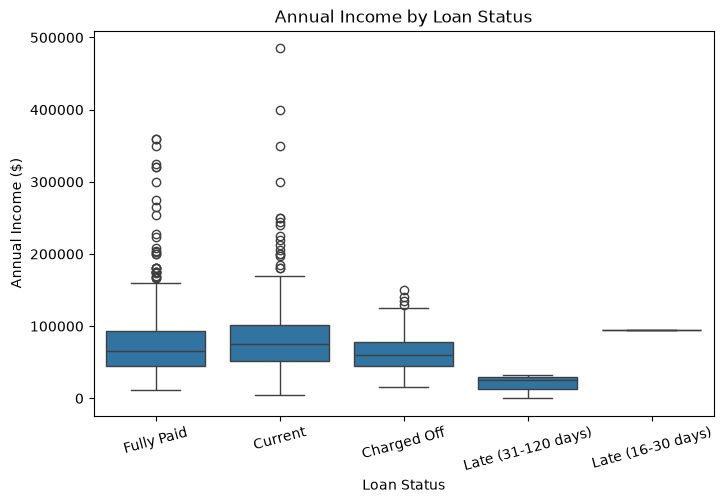

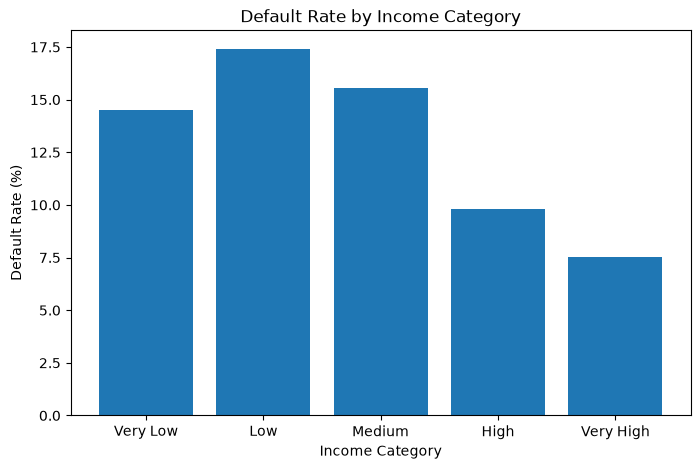

In [12]:
risk_df["annual_inc"].describe().round(2)

plt.figure(figsize=(8,5))

sns.histplot(
    data=risk_df,
    x="annual_inc",
    bins=30
)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income ($)")
plt.ylabel("Number of Borrowers")

plt.show()


income_by_status=(
    risk_df.groupby("loan_status")["annual_inc"].mean().sort_values().round(2)
)

income_by_status

plt.figure(figsize=(8,5))

sns.boxplot(
    data=risk_df,
    x="loan_status",
    y="annual_inc"
)
plt.title("Annual Income by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Annual Income ($)")

plt.xticks(rotation=15)

plt.show()


risk_df["income_category"]=pd.qcut(
    risk_df["annual_inc"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"]
)

risk_df["income_category"].value_counts().sort_index()


income_default_rate=(
    risk_df.groupby("income_category", observed=False)["default_flag"].mean()*100
)

plt.figure(figsize=(8,5))

plt.bar(
    x=income_default_rate.index,
    height=income_default_rate.values
)
plt.title("Default Rate by Income Category")
plt.xlabel("Income Category")
plt.ylabel("Default Rate (%)")

plt.show()



### Business Insights

The annual income distribution is strongly right-skewed, with most borrowers earning between approximately $40,000 and $100,000 per year. A relatively small number of borrowers report very high incomes, creating several high-income outliers.

The boxplot shows that borrowers with Current and Fully Paid loans generally have slightly higher incomes than those whose loans were Charged Off. However, the income distributions overlap considerably, indicating that annual income alone does not clearly separate low-risk and high-risk borrowers.

The default rate analysis reveals that borrowers in the High and Very High income categories have noticeably lower default rates than borrowers in the lower income groups. While the relationship is not perfectly linear across all categories, the overall trend suggests that higher income is associated with lower credit risk.

These findings indicate that annual income is an important predictor of loan performance, but it should be evaluated together with other borrower characteristics such as debt-to-income ratio, interest rate, and employment history.

## Loan Purpose and Default Risk

**Business Question**

Does the purpose of a loan influence the likelihood of default?

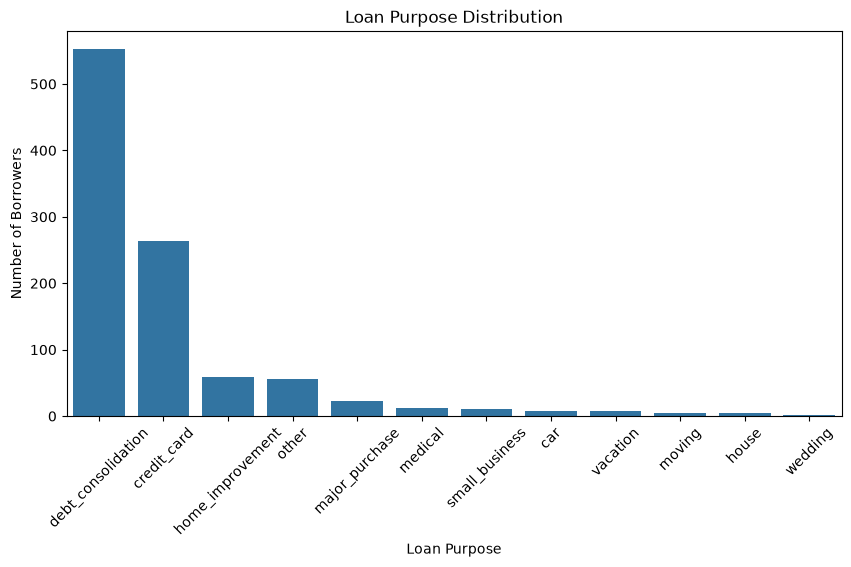

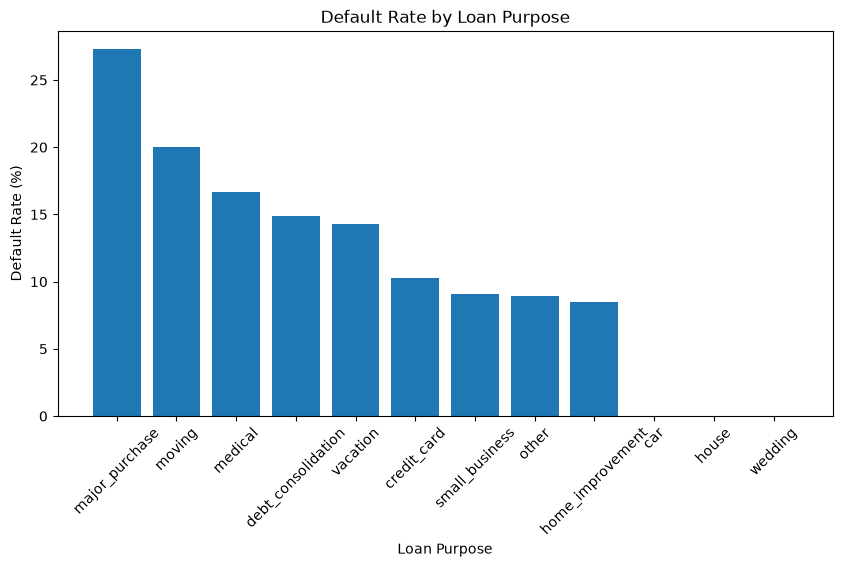

In [13]:

risk_df["purpose"].value_counts()

plt.figure(figsize=(10,5))

sns.countplot(
    data=risk_df,
    x="purpose",
    order=risk_df["purpose"].value_counts().index
)

plt.title("Loan Purpose Distribution")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Borrowers")

plt.xticks(rotation=45)

plt.show()


purpose_default_rate = (
    risk_df.groupby("purpose")["default_flag"].mean().sort_values(ascending=False) *100
)

purpose_default_rate.round(2)

plt.figure(figsize=(10,5))

plt.bar(
    x=purpose_default_rate.index,
    height=purpose_default_rate.values
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=45)

plt.show()

## Business Insights

The majority of borrowers use loans for debt consolidation, followed by credit card refinancing. Other loan purposes, such as medical expenses, moving, or weddings, represent only a small portion of the dataset.

The default rate varies across loan purposes. Categories such as major purchase, moving, and medical show the highest default rates. However, these categories contain relatively few observations, so their results should be interpreted with caution.

Among the larger loan categories, debt consolidation has a noticeably higher default rate than credit card and home improvement loans. Since debt consolidation loans account for the largest share of the portfolio, this category has the greatest impact on the lender's overall credit risk.

Overall, loan purpose appears to provide useful information for credit risk assessment, although conclusions should be based primarily on categories with sufficient numbers of borrowers.

### M5+ Grade and Default Risk

**Business Question**

How does the assigned loan grade relate to the probability of default?


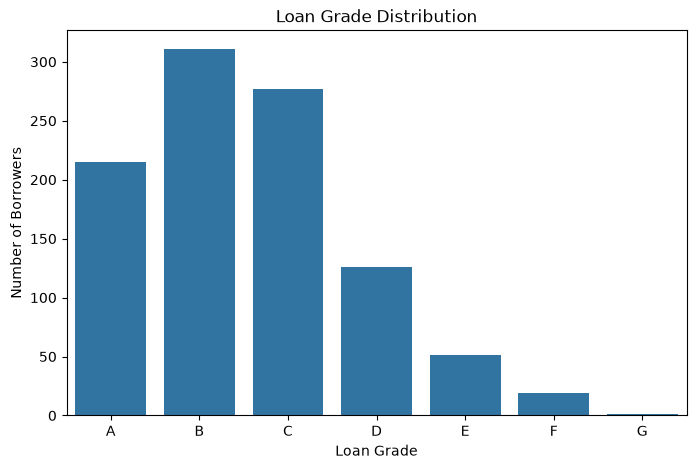

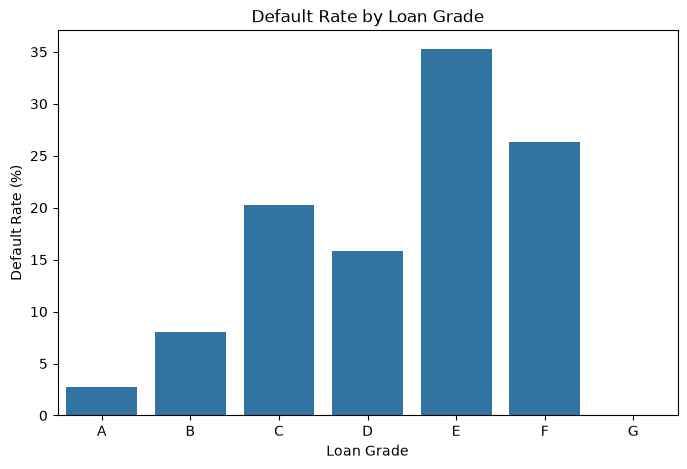

In [66]:

risk_df["grade"].value_counts().sort_index()

plt.figure(figsize=(8,5))

sns.countplot(
    data=risk_df,
    x="grade",
    order=sorted(risk_df["grade"].unique())
)

plt.title("Loan Grade Distribution")
plt.xlabel("Loan Grade")
plt.ylabel("Number of Borrowers")

plt.show()


grade_default = (
    risk_df.groupby("grade", observed=False)["default_flag"].mean().mul(100).round(2).sort_index()
)

grade_default

plt.figure(figsize=(8,5))

sns.barplot(
    x=grade_default.index,
    y=grade_default.values
)

plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.savefig("../images/default_rate_by_grade.png", dpi=300, bbox_inches="tight")
plt.show()

## Business Insights

Most loans in the dataset are assigned to grades B and C, while relatively few borrowers receive the highest-risk grades (F and G). This suggests that the lending portfolio is concentrated around medium-risk borrowers.

The default rate generally increases as loan grade worsens. Grade A loans have the lowest default rate, while grades C, D, E, and F show substantially higher default rates. Although there are slight changes between the highest-risk grades due to the limited number of observations, the overall trend is clear.

These findings indicate that the Lending Club grading system effectively reflects borrower risk. Loan grade appears to be one of the strongest indicators of default probability and is likely to be an important feature in predictive credit risk models.

### Revolving Utilization and Default Risk

**Business Question**

Are borrowers who use a larger percentage of their available credit more likely to default on their loans?

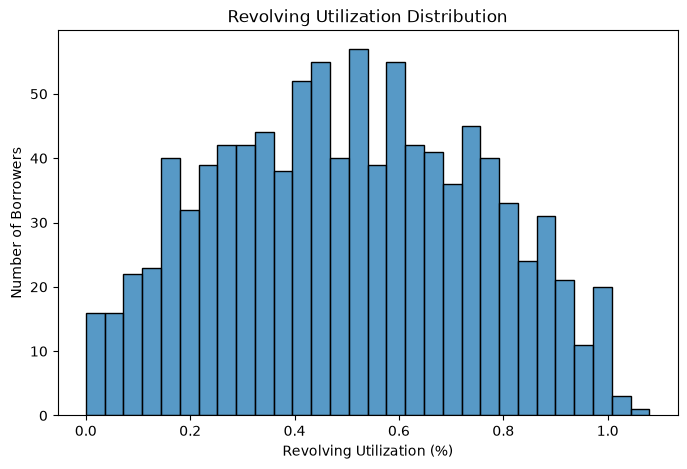

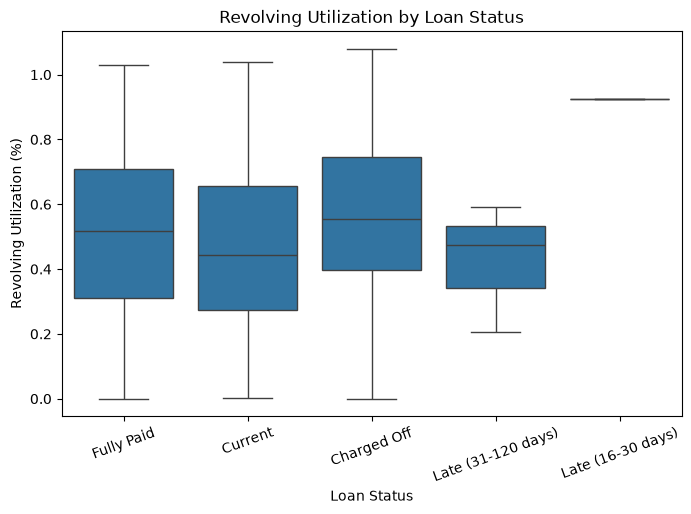

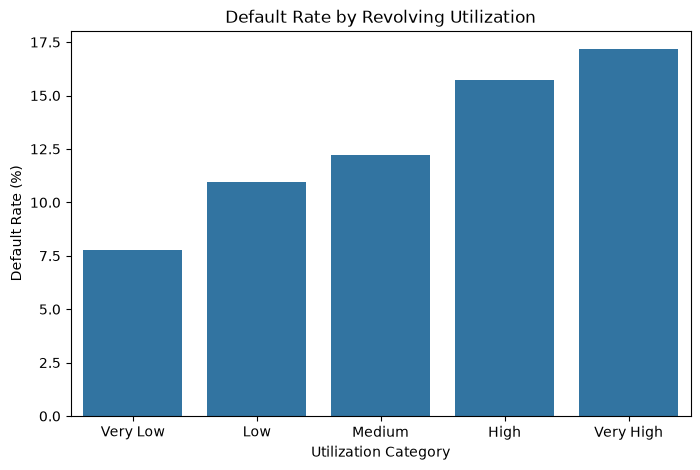

In [15]:
risk_df["revol_util"].describe().round(2)

plt.figure(figsize=(8,5))

sns.histplot(
    data=risk_df,
    x="revol_util",
    bins=30
)

plt.title("Revolving Utilization Distribution")
plt.xlabel("Revolving Utilization (%)")
plt.ylabel("Number of Borrowers")

plt.show()

plt.figure(figsize=(8,5))

sns.boxplot(
    data=risk_df,
    x="loan_status",
    y="revol_util"
)

plt.title("Revolving Utilization by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Revolving Utilization (%)")

plt.xticks(rotation=20)

plt.show()
risk_df["util_category"] = pd.cut(
    risk_df["revol_util"],
    bins=[0, 0.20, 0.40, 0.60, 0.80, 1.20],
    labels=["Very Low","Low","Medium","High","Very High"]
)

risk_df["util_category"].value_counts().sort_index()

util_default = (
    risk_df.groupby("util_category", observed=False)["default_flag"].mean().mul(100).round(2)
)

util_default

plt.figure(figsize=(8,5))

sns.barplot(
    x=util_default.index,
    y=util_default.values
)

plt.title("Default Rate by Revolving Utilization")
plt.xlabel("Utilization Category")
plt.ylabel("Default Rate (%)")

plt.show()

## Business Insights

Most borrowers use between 30% and 70% of their available revolving credit, while very low and extremely high utilization levels are less common.

The boxplot shows that borrowers whose loans were Charged Off generally have higher revolving utilization than borrowers who fully repaid their loans. This suggests that borrowers relying more heavily on existing credit tend to experience greater financial stress.

The default rate increases steadily across utilization categories, rising from approximately 8% for borrowers with very low utilization to around 17% for borrowers with very high utilization.

These findings indicate that revolving credit utilization is an important indicator of credit risk. Borrowers using a larger share of their available credit are more likely to default, making this variable valuable for credit risk assessment and lending decisions.

### Correlation Analysis

**Business Question**

Which numerical features are most strongly associated with loan default, and how are the variables related to each other?

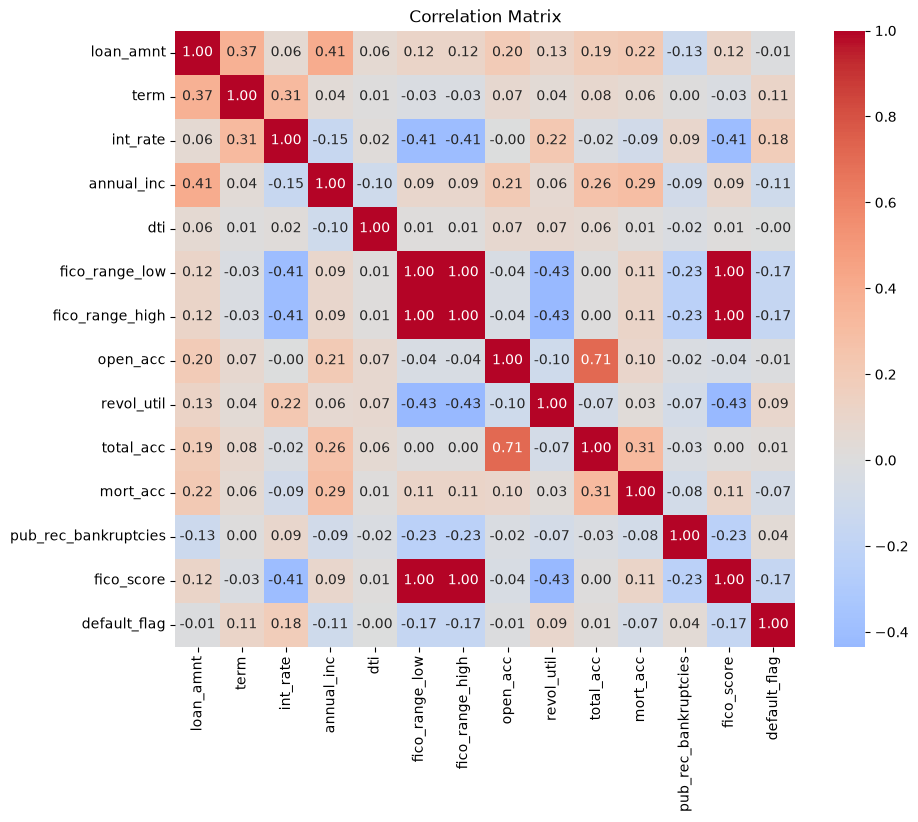

In [68]:
numeric_df = risk_df.select_dtypes(include="number")

corr_matrix = numeric_df.corr()

plt.figure(figsize=(10,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.savefig("../images/correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## Business Insights

The correlation analysis shows that no single numerical variable has a very strong linear relationship with loan default. This suggests that default behavior is influenced by multiple factors rather than one characteristic alone.

Among the analyzed variables, interest rate has the strongest positive correlation with default, indicating that borrowers with higher interest rates are more likely to default. FICO score shows the strongest negative correlation, confirming that borrowers with better credit scores generally present lower credit risk.

The heatmap also reveals several meaningful relationships between explanatory variables. Borrowers with higher annual income tend to receive larger loans, while larger loan amounts are associated with longer repayment terms. In addition, higher FICO scores are linked to lower interest rates and lower revolving credit utilization, reflecting healthier credit profiles.

Overall, the correlation analysis supports the findings from the previous exploratory analyses and confirms that interest rate, FICO score, and revolving credit utilization are among the most informative numerical indicators of credit risk.

### Interest Rate, Grade and Default Risk

**Business Question**

How are loan grade and interest rate related, and how do they jointly affect loan default risk?


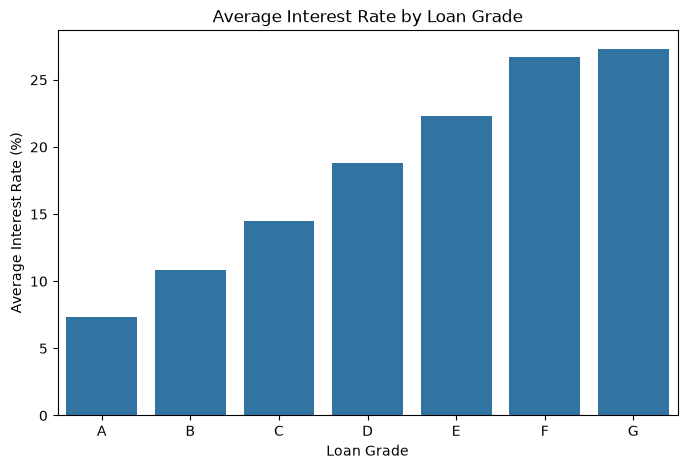

In [17]:
grade_interest=(
    risk_df.groupby("grade", observed=False)["int_rate"].mean().mul(100).round(2)
)

grade_interest

plt.figure(figsize=(8,5))

sns.barplot(
    x=grade_interest.index,
    y=grade_interest.values
)

plt.title("Average Interest Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Average Interest Rate (%)")

plt.show()






## Business Insights

The average interest rate increases steadily from Grade A to Grade G. Borrowers with the best credit quality (Grade A) receive the lowest interest rates, while higher-risk borrowers (Grades F and G) pay the highest rates. This confirms that the loan grading system is closely aligned with pricing, making loan grade one of the most informative variables for explaining interest rate differences. 

## Loan Amount and Interest Rate

**Business Question**

Do larger loans tend to have interest rates?

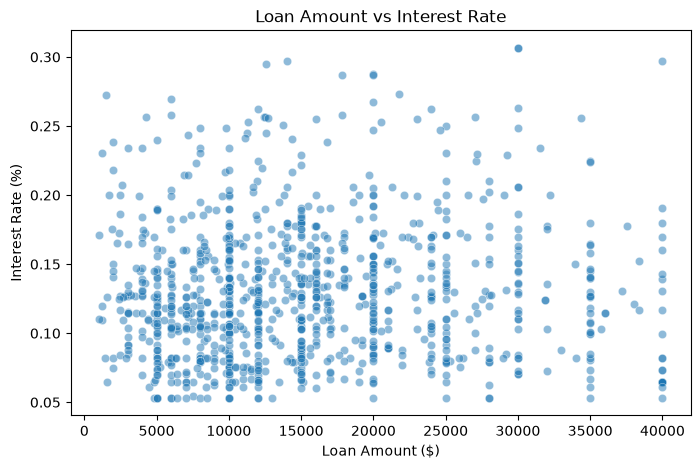

In [18]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=risk_df,
    x="loan_amnt",
    y="int_rate",
    alpha=0.5
)

plt.title("Loan Amount vs Interest Rate")
plt.xlabel("Loan Amount ($)")
plt.ylabel("Interest Rate (%)")

plt.show()

## Business Insights

The scatter plot does not show a clear relationship between loan amount and interest rate. Borrowers with similar loan amounts receive a wide range of interest rates, suggesting that loan size alone is not a strong determinant of pricing. Instead, interest rates appear to be driven primarily by borrower credit quality and risk characteristics.

## Interest Rate and Default Risk

**Business Question**

Is a higher interest rate associated with a higher probability of default?

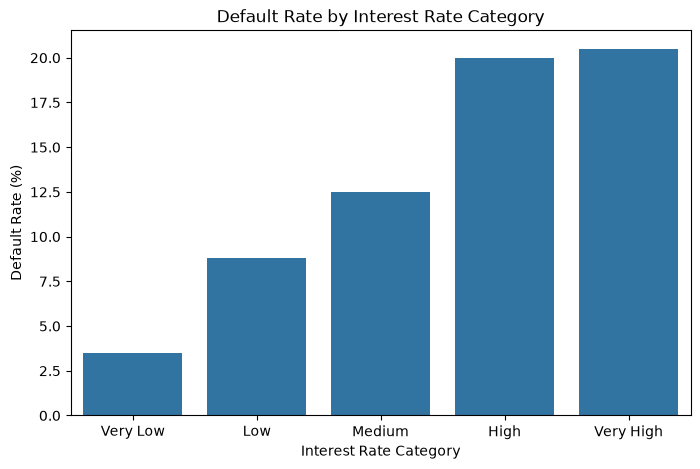

,min,max
interest_category,,
Very Low,5.31,8.38
Low,8.39,11.39
Medium,11.44,13.49
High,13.56,16.91
Very High,16.95,30.65


In [19]:
risk_df["interest_category"] = pd.qcut(
    risk_df["int_rate"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"]
)

risk_df["interest_category"].value_counts().sort_index()

interest_default_rate = (
    risk_df.groupby("interest_category", observed=False)["default_flag"].mean().mul(100).round(2)
)

interest_default_rate

plt.figure(figsize=(8,5))

sns.barplot(
    x=interest_default_rate.index,
    y=interest_default_rate.values
)

plt.title("Default Rate by Interest Rate Category")
plt.xlabel("Interest Rate Category")
plt.ylabel("Default Rate (%)")

plt.show()

risk_df.groupby(
    "interest_category",
    observed=False)["int_rate"].agg(["min", "max"]).mul(100).round(2)

### Business Insight

The default rate increases consistently across interest rate categories. Borrowers receiving loans with higher interest rates are substantially more likely to default than those with lower interest rates. This indicates that interest rates effectively reflect borrower credit risk and serve as a strong indicator of default probability.

# Machine Learning

In this section, machine learning models are developed to predict whether a borrower is likely to default on a loan. The goal is to build predictive models using the cleaned dataset and evaluate their performance on unseen data.

## Data Preparation

**Business Question**

How should the data be prepared before training machine learning models?

In [20]:
risk_df.columns.tolist()

['loan_status',
 'loan_amnt',
 'term',
 'int_rate',
 'grade',
 'sub_grade',
 'emp_length',
 'home_ownership',
 'annual_inc',
 'verification_status',
 'purpose',
 'dti',
 'fico_range_low',
 'fico_range_high',
 'open_acc',
 'revol_util',
 'total_acc',
 'mort_acc',
 'pub_rec_bankruptcies',
 'fico_score',
 'fico_category',
 'dti_category',
 'default_flag',
 'interest_category',
 'loan_amount_category',
 'income_category',
 'util_category']

### Feature Selection

The target variable is `default_flag`, where 1 represents a defaulted loan and 0 represents a non-defaulted loan.

Only variables that would be available at the time of the lending decision are considered as predictors. Variables that directly reveal the final loan outcome are excluded to prevent data leakage.

In [21]:
y=risk_df['default_flag']
y.value_counts()

default_flag
0    870
1    130
Name: count, dtype: int64

#### Class Distribution

The target variable is imbalanced. Approximately 87% of the loans are non-defaults, while 13% are defaults.

Because of this imbalance, accuracy alone may not provide a reliable measure of model performance. Additional evaluation metrics such as precision, recall, F1-score and ROC-AUC will therefore be considered.

In [22]:
features = [
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "dti",
    "open_acc",
    "revol_util",
    "total_acc",
    "mort_acc",
    "pub_rec_bankruptcies",
    "fico_score"
]

X = risk_df[features]

X.head()

,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,open_acc,revol_util,total_acc,mort_acc,pub_rec_bankruptcies,fico_score
0,20000,36,0.2474,E,E3,10+ years,MORTGAGE,76000.0,Not Verified,home_improvement,3.17,8,0.371,17,5,0,667.0
1,8300,36,0.0944,B,B1,3 years,RENT,54000.0,Source Verified,debt_consolidation,16.91,5,0.307,7,0,1,682.0
2,28000,60,0.1274,C,C1,4 years,OWN,225000.0,Source Verified,home_improvement,10.27,14,0.715,25,4,0,712.0
3,19500,60,0.1416,C,C2,6 years,MORTGAGE,59000.0,Not Verified,debt_consolidation,22.43,13,0.620,20,1,0,677.0
4,35000,36,0.0531,A,A1,10+ years,MORTGAGE,300000.0,Verified,debt_consolidation,23.83,26,0.303,43,4,0,757.0


### Feature Preprocessing

The selected features contain both numerical and categorical variables. Before model training, categorical variables must be converted into a numerical representation.

Ordinal variables have a meaningful order and will be encoded while preserving that order. Nominal categorical variables have no natural ranking and will therefore be transformed using one-hot encoding.

In [23]:
numeric_features = [
    "loan_amnt",
    "term",
    "int_rate",
    "annual_inc",
    "dti",
    "open_acc",
    "revol_util",
    "total_acc",
    "mort_acc",
    "pub_rec_bankruptcies",
    "fico_score"
]

ordinal_features = [
    "grade",
    "sub_grade",
    "emp_length"
]

nominal_features = [
    "home_ownership",
    "verification_status",
    "purpose"
]

len(numeric_features), len(ordinal_features), len(nominal_features)

(11, 3, 3)

### Train-Test Split

The dataset is divided into training and test sets so that model performance can be evaluated on observations that were not used during training.

The training set is used to learn patterns between borrower characteristics and loan default, while the test set is kept separate and used only for final model evaluation.

In [24]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=13,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).round(3))

X_train shape: (800, 17)
X_test shape: (200, 17)

Training target distribution:
default_flag
0    0.87
1    0.13
Name: proportion, dtype: float64

Test target distribution:
default_flag
0    0.87
1    0.13
Name: proportion, dtype: float64


In [25]:
%pip install scikit-learn



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Preprocessing Pipeline

Different preprocessing techniques are applied depending on the type of feature. Numerical features are standardized, ordinal features are encoded while preserving their natural order, and nominal categorical features are transformed using one-hot encoding.

In [26]:
from sklearn.preprocessing import StandardScaler

numeric_transformer= StandardScaler()

In [27]:
for column in ordinal_features:
    print(f"\n{column}:")
    print(X_train[column].value_counts(dropna=False))



grade:
grade
B    254
C    225
A    173
D     92
E     40
F     15
G      1
Name: count, dtype: int64

sub_grade:
sub_grade
B1    54
B5    53
B2    51
B3    49
C5    48
C1    47
B4    47
A5    47
C4    47
C2    46
C3    37
A1    37
A4    37
A2    31
D2    24
D3    22
D1    21
A3    21
D4    14
E1    13
D5    11
E5     9
E3     7
E2     6
E4     5
F2     5
F5     4
F3     3
F1     2
G2     1
F4     1
Name: count, dtype: int64

emp_length:
emp_length
10+ years    265
< 1 year      77
2 years       75
Unknown       57
3 years       55
5 years       54
1 year        50
4 years       46
8 years       35
7 years       29
6 years       29
9 years       28
Name: count, dtype: int64


In [28]:
grade_order = ["A", "B", "C", "D", "E", "F", "G"]

sub_grade_order = [
    f"{grade}{number}"
    for grade in "ABCDEFG"
    for number in range(1, 6)
]

emp_length_order = [
    "< 1 year",
    "1 year",
    "2 years",
    "3 years",
    "4 years",
    "5 years",
    "6 years",
    "7 years",
    "8 years",
    "9 years",
    "10+ years"
]

grade_order= ["A", "B", "C", "D", "E", "F", "G"]

sub_grade_order=[
    f"{grade}{number}"
    for grade in "ABCDEFG"
    for number in range(1,6)
]

emp_length_order=[
    "< 1 year",
    "1 year",
    "2 years",
    "3 years",
    "4 years",
    "5 years",
    "6 years",
    "7 years",
    "8 years",
    "9 years",
    "10+ years"
]

In [29]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_transformer= OrdinalEncoder(
    categories=[
        grade_order,
        sub_grade_order,
        emp_length_order
    ],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

In [30]:
from sklearn.preprocessing import OneHotEncoder

nominal_transformer= OneHotEncoder(
    handle_unknown="ignore"
)

In [31]:
from sklearn.compose import ColumnTransformer

preprocessor= ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("ord", ordinal_transformer, ordinal_features),
        ("nom", nominal_transformer, nominal_features)
    ]
)

In [32]:
from sklearn.linear_model import LogisticRegression

logistic_model= LogisticRegression(
    max_iter=1000,
    random_state=13
)

In [33]:
from sklearn.pipeline import Pipeline

logistic_pipeline= Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", logistic_model)
    ]
)

### Logistic Regression

Logistic Regression is used as the baseline classification model. It estimates the probability that a borrower will default based on the selected loan and borrower characteristics.

In [34]:
logistic_pipeline.fit(X_train, y_train)

y_pred= logistic_pipeline.predict(X_test)

In [35]:
print("Predicted classes:")
print(pd.Series(y_pred).value_counts())

Predicted classes:
0    200
Name: count, dtype: int64


In [36]:
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

print(y_prob[:20])

print("\nMinimum probability:", y_prob.min())
print("Maximum probability:", y_prob.max())
print("Average probability:", y_prob.mean())

[0.16869062 0.40547758 0.02473095 0.22280138 0.01046355 0.09436892
 0.25939189 0.04899564 0.26972131 0.04598986 0.03939614 0.17732977
 0.0794024  0.07437674 0.01719039 0.39041142 0.02718477 0.00990745
 0.01362172 0.08014925]

Minimum probability: 0.0016485617702178778
Maximum probability: 0.49161814917542074
Average probability: 0.1315857644497735


In [37]:
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

print(y_prob[:20])

print("\nMinimum probability:", y_prob.min())
print("Maximum probability:", y_prob.max())
print("Average probability:", y_prob.mean())

[0.16869062 0.40547758 0.02473095 0.22280138 0.01046355 0.09436892
 0.25939189 0.04899564 0.26972131 0.04598986 0.03939614 0.17732977
 0.0794024  0.07437674 0.01719039 0.39041142 0.02718477 0.00990745
 0.01362172 0.08014925]

Minimum probability: 0.0016485617702178778
Maximum probability: 0.49161814917542074
Average probability: 0.1315857644497735


In [38]:
from sklearn.metrics import confusion_matrix

cm= confusion_matrix(y_test, y_pred)

print(cm)


[[174   0]
 [ 26   0]]


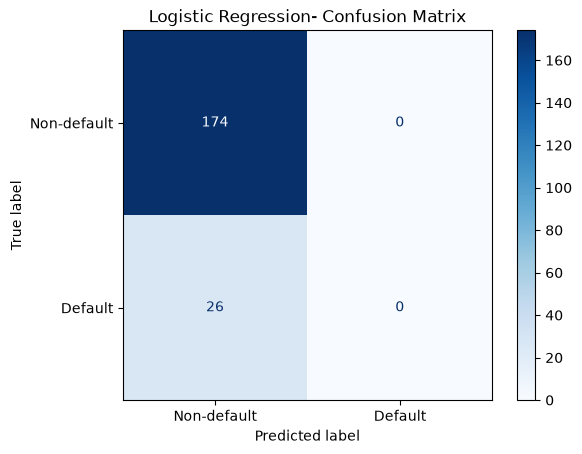

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Non-default", "Default"],
    cmap="Blues"
)

plt.title("Logistic Regression- Confusion Matrix")
plt.show()

In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy= accuracy_score(y_test, y_pred)
precision= precision_score(y_test, y_pred, zero_division=0)
recall= recall_score(y_test, y_pred)
f1= f1_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-score:", round(f1, 3))


Accuracy: 0.87
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [41]:
from sklearn.metrics import roc_auc_score

roc_auc= roc_auc_score(y_test, y_prob)

print("ROC-AUC:", round(roc_auc, 3))

ROC-AUC: 0.734


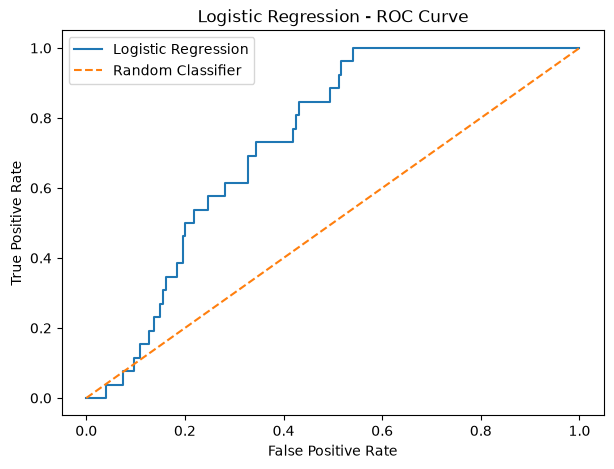

In [69]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds= roc_curve(y_test, y_prob)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label="Logistic Regression"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - ROC Curve")
plt.legend()
plt.savefig("../images/roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

### ROC Curve

The Logistic Regression model achieved a ROC-AUC score of 0.734. The ROC curve is mostly above the random classifier line, which shows that the model has some ability to distinguish between default and non-default borrowers.

Even though the model predicted no defaults using the default threshold of 0.50, the ROC-AUC score shows that the predicted probabilities still contain useful information about borrower risk. This suggests that the choice of classification threshold will be important for improving the final predictions.

In [43]:
from sklearn.metrics import average_precision_score

pr_auc= average_precision_score(y_test, y_prob)

print("Average Precision:", round(pr_auc, 3))

Average Precision: 0.218


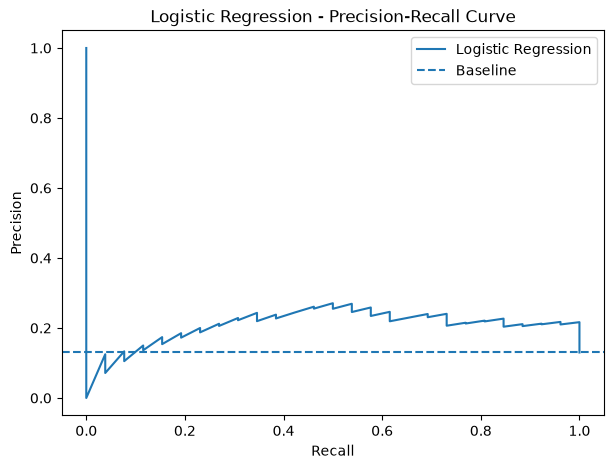

In [70]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds= precision_recall_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7,5))

plt.plot(
    recall,
    precision,
    label= "Logistic Regression"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression - Precision-Recall Curve")
plt.axhline(
    y=y_test.mean(),   #y_test sadrži samo 0 i 1, pa je njegov prosek je upravo procenat jedinica 26.200=0.13
    linestyle="--",
    label="Baseline"
)
plt.legend()
plt.savefig("../images/precision_recall_curve.png", dpi=300, bbox_inches="tight")
plt.show()

### Precision–Recall Curve

The Precision–Recall curve shows how precision and recall change at different classification thresholds.

The Average Precision score is 0.218, while defaults represent about 13% of the test data. The model performs above this baseline, which shows that it has some ability to identify borrowers with higher default risk. However, the relatively low precision also shows that identifying more defaults would result in more non-default borrowers being incorrectly classified as risky.

### Cross-Validation

To obtain a more reliable estimate of the model's performance, 5-fold stratified cross-validation is applied to the training data. Stratification keeps a similar proportion of default and non-default loans in each fold.

The test set is kept separate and is not used during cross-validation.

In [45]:
from sklearn.model_selection import StratifiedKFold

cv= StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=13
)

In [46]:
from sklearn.model_selection import cross_val_score

cv_scores= cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("ROC-AUC scores:", cv_scores)
print("Mean ROC-AUC:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

ROC-AUC scores: [0.65821429 0.68208291 0.74991435 0.66563892 0.75676602]
Mean ROC-AUC: 0.703
Standard deviation: 0.042


The Logistic Regression model achieved a mean cross-validation ROC-AUC of 0.703, with a standard deviation of 0.042 across the five folds. The individual scores ranged from approximately 0.658 to 0.757.

This shows that the model has a moderate ability to distinguish between default and non-default borrowers, although its performance varies somewhat across different subsets of the training data. The cross-validation result is also reasonably close to the ROC-AUC of 0.734 obtained on the test set.

In [47]:
from sklearn.model_selection import cross_val_predict

y_train_prob= cross_val_predict(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:,1]

#mogli smo da napisemo i logistic_pipeline.predict_proba(X_train), ali tada bi model davao predikcije za podatke na kojima je vec ucio
#za cross_val_predict svaki klijent dobija prediction samo onda kada je bio u validation foldu

print(y_train_prob[:20])

print("\nMinimum probability:", y_train_prob.min())
print("Maximum probability:", y_train_prob.max())
print("Average probability:", y_train_prob.mean())

[0.04569351 0.03141835 0.1280695  0.07970592 0.03089382 0.1797242
 0.05680574 0.0238367  0.22116242 0.12945088 0.04608859 0.04228989
 0.13128525 0.06606803 0.05102531 0.04505456 0.02899324 0.10501788
 0.25680209 0.08385051]

Minimum probability: 0.001624083601208265
Maximum probability: 0.7838614679603334
Average probability: 0.13203192325006016


### Classification Threshold Analysis

The default threshold of 0.50 resulted in very low recall for the default class. To examine this further, several classification thresholds were evaluated using out-of-fold predictions from the training data.

In [48]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    y_train_pred = (y_train_prob >= threshold).astype(int)

    precision = precision_score(y_train, y_train_pred, zero_division=0)
    recall = recall_score(y_train, y_train_pred)
    f1 = f1_score(y_train, y_train_pred)

    threshold_results.append([
        threshold,
        precision,
        recall,
        f1
    ])

threshold_df = pd.DataFrame(
    threshold_results,
    columns=["Threshold", "Precision", "Recall", "F1-score"]
)

print(threshold_df.round(3))

   Threshold  Precision  Recall  F1-score
0       0.10      0.195   0.712     0.306
1       0.15      0.239   0.558     0.334
2       0.20      0.268   0.394     0.319
3       0.25      0.304   0.298     0.301
4       0.30      0.300   0.202     0.241
5       0.40      0.289   0.106     0.155
6       0.50      0.304   0.067     0.110


Lowering the classification threshold increases recall, allowing the model to identify more actual defaults, but also reduces precision because more non-default borrowers are classified as risky.

Among the tested thresholds, 0.15 achieved the highest F1-score of 0.334, with a recall of 0.558 and precision of 0.239. This provides a better balance between identifying defaults and limiting false positive predictions than the default threshold of 0.50.

The final threshold would depend on the bank's priorities. If identifying as many potential defaults as possible is more important, a lower threshold could be used to increase recall. If avoiding incorrectly classifying non-default borrowers as risky is more important, a higher threshold may be preferred.

### Handling Class Imbalance

Since defaulted loans represent a much smaller part of the dataset, a second Logistic Regression model is trained using balanced class weights. This gives more importance to the minority default class during training.

The balanced model will be compared with the baseline Logistic Regression model using the same cross-validation approach.

In [49]:
balanced_logistic_model= LogisticRegression(
    max_iter=1000,
    random_state=13,
    class_weight="balanced"
)

balanced_logistic_pipeline= Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", balanced_logistic_model)
    ]
)

balanced_cv_scores= cross_val_score(
    balanced_logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("ROC-AUC scores:", balanced_cv_scores)
print("Mean ROC-AUC:", round(balanced_cv_scores.mean(), 3))
print("Standard deviation:", round(balanced_cv_scores.std(), 3))




ROC-AUC scores: [0.67357143 0.68002741 0.74340528 0.6618705  0.75813635]
Mean ROC-AUC: 0.703
Standard deviation: 0.039


In [50]:
balanced_logistic_model= LogisticRegression(
    max_iter=1000,
    random_state=13,
    class_weight="balanced"
)

balanced_logistic_pipeline= Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", balanced_logistic_model)
    ]
)

balanced_cv_scores= cross_val_score(
    balanced_logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("ROC-AUC scores:", balanced_cv_scores)
print("Mean ROC-AUC:", round(balanced_cv_scores.mean(), 3))
print("Standard deviation:", round(balanced_cv_scores.std(), 3))




ROC-AUC scores: [0.67357143 0.68002741 0.74340528 0.6618705  0.75813635]
Mean ROC-AUC: 0.703
Standard deviation: 0.039


In [51]:
balanced_logistic_model= LogisticRegression(
    max_iter=1000,
    random_state=13,
    class_weight="balanced"
)

balanced_logistic_pipeline= Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", balanced_logistic_model)
    ]
)

balanced_cv_scores= cross_val_score(
    balanced_logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("ROC-AUC scores:", balanced_cv_scores)
print("Mean ROC-AUC:", round(balanced_cv_scores.mean(), 3))
print("Standard deviation:", round(balanced_cv_scores.std(), 3))




ROC-AUC scores: [0.67357143 0.68002741 0.74340528 0.6618705  0.75813635]
Mean ROC-AUC: 0.703
Standard deviation: 0.039


Using balanced class weights did not improve the cross-validation ROC-AUC score, which remained at 0.703. Therefore, the baseline Logistic Regression model is kept for further comparison.

## Decision Tree

A Decision Tree is used as a second classification model. Unlike Logistic Regression, it makes predictions by repeatedly splitting the data based on feature values.

The depth of the tree is limited to reduce the risk of overfitting.

In [52]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model= DecisionTreeClassifier(
    max_depth=4,
    random_state=13
)

decision_tree_pipeline=Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", decision_tree_model)
    ]
)

tree_cv_scores= cross_val_score(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("ROC-AUC scores:", tree_cv_scores)
print("Mean ROC-AUC:", round(tree_cv_scores.mean(), 3))
print("Standard deviation:", round(tree_cv_scores.std(), 3))






ROC-AUC scores: [0.68517857 0.65827338 0.6618705  0.66837958 0.7509421 ]
Mean ROC-AUC: 0.685
Standard deviation: 0.034


The Decision Tree achieved a mean cross-validation ROC-AUC of 0.685, which is slightly lower than the 0.703 achieved by Logistic Regression. With the current settings, Logistic Regression therefore performs better at distinguishing between default and non-default borrowers.

In [53]:
    depths=[2,3,4,5,6,8]

    for depth in depths:
        tree_model= DecisionTreeClassifier(
            max_depth=depth,
            random_state=13
        )

        tree_pipeline= Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                ("model", tree_model)
            ]
        )

        scores= cross_val_score(
            tree_pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring="roc_auc"
        )

        print(
            "Max depth:", depth,
            "| Mean ROC-AUC:", round(scores.mean(),3)
        )

Max depth: 2 | Mean ROC-AUC: 0.661
Max depth: 3 | Mean ROC-AUC: 0.675
Max depth: 4 | Mean ROC-AUC: 0.685
Max depth: 5 | Mean ROC-AUC: 0.656
Max depth: 6 | Mean ROC-AUC: 0.606
Max depth: 8 | Mean ROC-AUC: 0.562


#### Hyperparameter Tuning

Several values of `max_depth` were compared using cross-validation. The best mean ROC-AUC was 0.685 at `max_depth=4`.

Performance improved as the tree depth increased up to 4, but decreased for deeper trees, suggesting that more complex trees were starting to overfit the training data. Therefore, `max_depth=4` was kept for the Decision Tree model.

## Random Forest

Random Forest combines predictions from multiple Decision Trees. Each tree is trained using a random sample of the training data and considers a random subset of features when making splits.

Combining multiple trees can produce a more stable model and reduce the overfitting that can occur with a single Decision Tree.

In [54]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model= RandomForestClassifier(
    n_estimators=100,
    random_state=13
)

random_forest_pipeline=Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", random_forest_model)
    ]
)

forest_cv_scores= cross_val_score(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("ROC-AUC scores:", forest_cv_scores)
print("Mean ROC-AUC:", round(forest_cv_scores.mean(), 3))
print("Standard deviation:", round(forest_cv_scores.std(), 3))

ROC-AUC scores: [0.58410714 0.64713943 0.69938335 0.5870161  0.7286742 ]
Mean ROC-AUC: 0.649
Standard deviation: 0.058


In [55]:
depths=[3,4,5,6,8,None]

for depth in depths:
    forest_model= RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=13
    )

    forest_pipeline=Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", forest_model)
        ]
    )

    scores= cross_val_score(
        forest_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    print(
        "Max_depth:", depth,
        "| Mean ROC-AUC:", round(scores.mean(), 3)
    )

Max_depth: 3 | Mean ROC-AUC: 0.7
Max_depth: 4 | Mean ROC-AUC: 0.697
Max_depth: 5 | Mean ROC-AUC: 0.691
Max_depth: 6 | Mean ROC-AUC: 0.692
Max_depth: 8 | Mean ROC-AUC: 0.666
Max_depth: None | Mean ROC-AUC: 0.649


### Hyperparameter Tuning

Different values of `max_depth` were compared using cross-validation. Limiting the depth improved the Random Forest performance considerably, with `max_depth=3` achieving the highest mean ROC-AUC of 0.700.

The performance decreased as the trees became deeper, suggesting that limiting tree complexity helps reduce overfitting on this dataset.

## Model Comparison

The three models are compared using their mean cross-validation ROC-AUC scores. Using the same cross-validation procedure allows the models to be compared under the same conditions.

In [56]:
final_tree_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=13
)

final_tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", final_tree_model)
    ]
)

final_tree_cv_scores = cross_val_score(
    final_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Mean ROC-AUC:", round(final_tree_cv_scores.mean(), 3))

Mean ROC-AUC: 0.685


In [57]:
final_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=3,
    random_state=13
)

final_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", final_forest_model)
    ]
)

final_forest_cv_scores = cross_val_score(
    final_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Mean ROC-AUC:", round(final_forest_cv_scores.mean(), 3))

Mean ROC-AUC: 0.7


In [58]:
model_comparison= pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Mean CV ROC-AUC": [
        cv_scores.mean(),
        final_tree_cv_scores.mean(),
        final_forest_cv_scores.mean()
    ]
})

model_comparison= model_comparison.sort_values(
    "Mean CV ROC-AUC",
    ascending=False
)

model_comparison

,Model,Mean CV ROC-AUC
0,Logistic Regression,0.702523
2,Random Forest,0.700297
1,Decision Tree,0.684929


Logistic Regression achieved the highest mean cross-validation ROC-AUC of 0.703, followed closely by Random Forest with 0.700. Decision Tree achieved a slightly lower score of 0.685.

The difference between Logistic Regression and Random Forest is very small, so there is no clear performance advantage of the more complex model. Logistic Regression is therefore selected as the mfinal model because it achieved the highest cross-validation score while also being simpler and easier to interpret.

## Final Model Evaluation

Logistic Regression was selected as the final model based on the cross-validation results.

The classification threshold of 0.15, selected using out-of-fold predictions from the training data, is now applied to the test set. This threshold is used instead of the default value of 0.50 to improve the model's ability to identify borrowers who default.

In [59]:
selected_threshold=0.15

y_pred_final= (y_prob>=selected_threshold).astype(int)

final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final, zero_division=0)
final_recall = recall_score(y_test, y_pred_final)
final_f1 = f1_score(y_test, y_pred_final)
final_roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", round(final_accuracy, 3))
print("Precision:", round(final_precision, 3))
print("Recall:", round(final_recall, 3))
print("F1-score:", round(final_f1, 3))
print("ROC-AUC:", round(final_roc_auc, 3))

Accuracy: 0.67
Precision: 0.222
Recall: 0.615
F1-score: 0.327
ROC-AUC: 0.734


[[118  56]
 [ 10  16]]


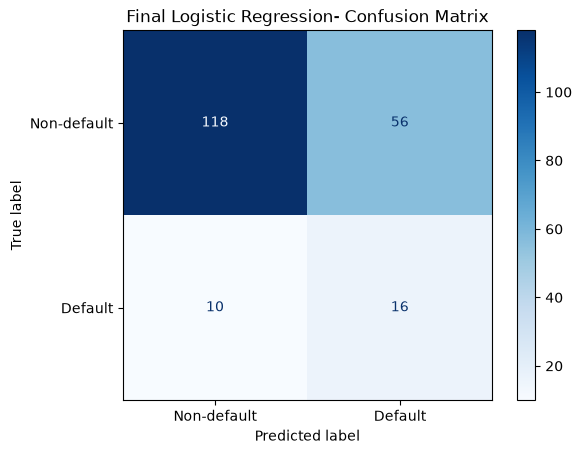

In [71]:
final_cm= confusion_matrix(y_test, y_pred_final)

print(final_cm)

ConfusionMatrixDisplay.from_predictions(
   y_test, 
   y_pred_final,
   display_labels=["Non-default", "Default"],
   cmap="Blues"
    
)

plt.title("Final Logistic Regression- Confusion Matrix")
plt.savefig("../images/final_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

Using the selected threshold of 0.15, the final Logistic Regression model achieved a recall of 0.615, meaning that it correctly identified 16 of the 26 defaulted loans in the test set.

The lower threshold improved the model's ability to detect defaults compared with the default threshold of 0.50, which identified none of them. However, this came at the cost of more false positives, with 56 non-default loans incorrectly classified as defaults.

The final ROC-AUC score of 0.734 shows that the model has a moderate ability to distinguish between borrowers with higher and lower default risk. The choice of threshold therefore represents a trade-off between detecting more potential defaults and incorrectly classifying non-default borrowers as risky.

## Model Interpretation

To better understand the final Logistic Regression model, its coefficients are examined. Positive coefficients are associated with a higher predicted probability of default, while negative coefficients are associated with a lower predicted probability of default.

In [61]:
feature_names= logistic_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

feature_names

array(['num__loan_amnt', 'num__term', 'num__int_rate', 'num__annual_inc',
       'num__dti', 'num__open_acc', 'num__revol_util', 'num__total_acc',
       'num__mort_acc', 'num__pub_rec_bankruptcies', 'num__fico_score',
       'ord__grade', 'ord__sub_grade', 'ord__emp_length',
       'nom__home_ownership_ANY', 'nom__home_ownership_MORTGAGE',
       'nom__home_ownership_OWN', 'nom__home_ownership_RENT',
       'nom__verification_status_Not Verified',
       'nom__verification_status_Source Verified',
       'nom__verification_status_Verified', 'nom__purpose_car',
       'nom__purpose_credit_card', 'nom__purpose_debt_consolidation',
       'nom__purpose_home_improvement', 'nom__purpose_house',
       'nom__purpose_major_purchase', 'nom__purpose_medical',
       'nom__purpose_moving', 'nom__purpose_other',
       'nom__purpose_small_business', 'nom__purpose_vacation',
       'nom__purpose_wedding'], dtype=object)

In [62]:
coefficients= logistic_pipeline.named_steps["model"].coef_[0]

coefficients

array([ 0.16754927,  0.11466505, -0.97670207, -0.40051081, -0.19802271,
       -0.21676122,  0.03300399,  0.33835596, -0.12475165, -0.07902293,
       -0.38413284,  0.40230723,  0.14437285,  0.00919326, -0.10108816,
       -0.23275038, -0.02473136,  0.36777592, -0.2259621 , -0.04944213,
        0.28461025, -0.61481002,  0.14119293, -0.01642441, -0.06202232,
       -0.2921797 ,  0.99991256,  0.13532455,  0.11188477, -0.10110363,
        0.19296139, -0.40639754, -0.07913256])

In [63]:
coefficient_df= pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df

,Feature,Coefficient
0,num__loan_amnt,0.167549
1,num__term,0.114665
2,num__int_rate,-0.976702
3,num__annual_inc,-0.400511
4,num__dti,-0.198023
5,num__open_acc,-0.216761
6,num__revol_util,0.033004
7,num__total_acc,0.338356
8,num__mort_acc,-0.124752
9,num__pub_rec_bankruptcies,-0.079023


In [64]:
coefficient_df["Absolute Coefficient"]= coefficient_df["Coefficient"].abs()

coefficient_df= coefficient_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

coefficient_df.head(10)


,Feature,Coefficient,Absolute Coefficient
26,nom__purpose_major_purchase,0.999913,0.999913
2,num__int_rate,-0.976702,0.976702
21,nom__purpose_car,-0.614810,0.614810
31,nom__purpose_vacation,-0.406398,0.406398
11,ord__grade,0.402307,0.402307
3,num__annual_inc,-0.400511,0.400511
10,num__fico_score,-0.384133,0.384133
17,nom__home_ownership_RENT,0.367776,0.367776
7,num__total_acc,0.338356,0.338356
25,nom__purpose_house,-0.292180,0.292180


The largest Logistic Regression coefficients show that several borrower and loan characteristics contribute to the predicted default risk.

Higher loan grades and renting a home are associated with a higher predicted probability of default, while higher annual income and FICO scores are associated with a lower predicted probability of default.

Some coefficients, particularly interest rate, should be interpreted carefully because several predictors such as interest rate, grade and sub-grade are strongly related. Therefore, individual coefficients do not necessarily represent independent or causal effects.

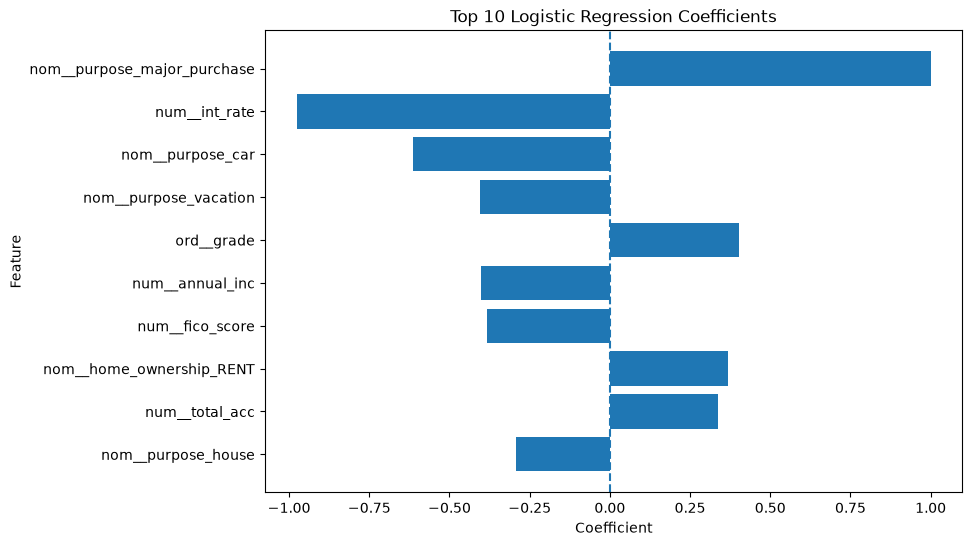

In [72]:
top_coefficients = coefficient_df.head(10)

plt.figure(figsize=(9, 6))

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"]
)

plt.axvline(0, linestyle="--")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top 10 Logistic Regression Coefficients")
plt.gca().invert_yaxis()
plt.savefig("../images/logistic_regression_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

# Conclusion

This project explored borrower and loan characteristics related to credit default risk and developed machine learning models for predicting loan defaults.

The exploratory analysis showed that variables such as loan grade, interest rate, FICO score and annual income were related to default risk. Borrowers with lower FICO scores and lower incomes generally showed higher default rates, while higher-risk loan grades were also associated with more defaults.

Three classification models were compared using stratified cross-validation: Logistic Regression, Decision Tree and Random Forest. Logistic Regression achieved the highest mean cross-validation ROC-AUC of 0.703, although Random Forest performed very similarly with a score of 0.700.

Logistic Regression was selected as the final model. On the test set, it achieved a ROC-AUC of 0.734. Using the selected classification threshold of 0.15, the model identified 16 of the 26 defaulted loans, resulting in a recall of 0.615 and precision of 0.222.

The results also showed the importance of choosing an appropriate classification threshold. The default threshold of 0.50 failed to identify any defaults, while lowering the threshold improved default detection at the cost of more false positive predictions.

Overall, the model shows a moderate ability to distinguish between higher- and lower-risk borrowers. However, the relatively small dataset and class imbalance limit the reliability of the predictions. A larger dataset and further model development could be used to improve performance in future work.